## Simple analysis of the numbers clean data

In [1]:
# read the data
import pandas as pd
numbers_df = pd.read_csv('../../../data/processed/the_numbers_worldwide_2026_cleaned.csv')

In [2]:
numbers_df.columns

Index(['rank', 'title', 'year', 'domestic_box_office',
       'international_box_office', 'worldwide_box_office', 'domestic_share',
       'url'],
      dtype='str')

In [3]:
# Dataset dimensions
print("Shape:", numbers_df.shape)

# Column types and non-null counts
numbers_df.info()

# First rows
display(numbers_df.head())

# Descriptive statistics for numerical columns
display(numbers_df.describe())

Shape: (800, 8)
<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 8 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   rank                      800 non-null    int64  
 1   title                     800 non-null    str    
 2   year                      800 non-null    int64  
 3   domestic_box_office       800 non-null    float64
 4   international_box_office  800 non-null    float64
 5   worldwide_box_office      800 non-null    float64
 6   domestic_share            800 non-null    float64
 7   url                       800 non-null    str    
dtypes: float64(4), int64(2), str(2)
memory usage: 50.1 KB


,rank,title,year,domestic_box_office,international_box_office,worldwide_box_office,domestic_share,url
0,1,Avengers: Endgame,2019,862173000.0,1.859131e+09,2.721304e+09,31.7,https://www.the-numbers.com/movie/Avengers-End...
1,2,The Lion King,2019,543638043.0,1.117816e+09,1.661454e+09,32.7,https://www.the-numbers.com/movie/Lion-King-Th...
2,3,Frozen II,2019,477373578.0,9.742797e+08,1.451653e+09,32.9,https://www.the-numbers.com/movie/Frozen-II-(2...
3,4,Spider-Man: Far From Home,2019,391362492.0,7.409362e+08,1.132299e+09,34.6,https://www.the-numbers.com/movie/Spider-Man-F...
4,5,Captain Marvel,2019,426829839.0,7.027463e+08,1.129576e+09,37.8,https://www.the-numbers.com/movie/Captain-Marv...


,rank,year,domestic_box_office,international_box_office,worldwide_box_office,domestic_share
count,800.000000,800.000000,8.000000e+02,8.000000e+02,8.000000e+02,800.000000
mean,50.500000,2022.500000,6.555747e+07,1.417874e+08,2.073448e+08,29.742750
std,28.884128,2.292721,1.171297e+08,2.108439e+08,3.064941e+08,26.511945
min,1.000000,2019.000000,0.000000e+00,0.000000e+00,1.215779e+07,0.000000
25%,25.750000,2020.750000,0.000000e+00,3.275937e+07,4.952300e+07,0.000000
50%,50.500000,2022.500000,2.278174e+07,7.018159e+07,1.028206e+08,32.950000
75%,75.250000,2024.250000,7.266605e+07,1.563874e+08,2.185397e+08,48.925000
max,100.000000,2026.000000,9.465821e+08,1.977904e+09,2.721304e+09,100.000000


In [4]:
# Missing values
print("Missing values per column:")
display(numbers_df.isnull().sum())

# Duplicate rows
print("Duplicate rows:", numbers_df.duplicated().sum())

# Duplicate movie titles
print("Duplicate titles:", numbers_df["title"].duplicated().sum())

# Number of unique movies and years
print("Unique titles:", numbers_df["title"].nunique())
print("Years covered:", sorted(numbers_df["year"].dropna().unique()))

Missing values per column:


rank                        0
title                       0
year                        0
domestic_box_office         0
international_box_office    0
worldwide_box_office        0
domestic_share              0
url                         0
dtype: int64

Duplicate rows: 0
Duplicate titles: 0
Unique titles: 800
Years covered: [np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025), np.int64(2026)]


In [13]:
box_office_cols = [
    "domestic_box_office",
    "international_box_office",
    "worldwide_box_office",
    "domestic_share"
]

# Most successful movies worldwide
display(
    numbers_df.nlargest(10, "worldwide_box_office")[
        ["rank", "title", "year", "domestic_box_office",
         "international_box_office", "worldwide_box_office","domestic_share"]
    ]
)

,rank,title,year,domestic_box_office,international_box_office,worldwide_box_office,domestic_share
0,1,Avengers: Endgame,2019,862173000.0,1.859131e+09,2.721304e+09,31.7
600,1,Spider-Man: Brand New Day,2026,946582066.0,1.534125e+09,2.480707e+09,38.2
200,1,Avatar: The Way of Water,2022,688809501.0,1.634093e+09,2.322902e+09,29.7
500,1,Ne Zha 2 (哪吒之魔童闹海),2025,23251218.0,1.977904e+09,2.001155e+09,1.2
700,1,Spider-Man: No Way Home,2021,814811535.0,1.106395e+09,1.921207e+09,42.4
501,2,Zootopia 2,2025,428130160.0,1.442179e+09,1.870309e+09,22.9
601,2,The Odyssey,2026,612118605.0,1.117692e+09,1.729811e+09,35.4
400,1,Inside Out 2,2024,652980194.0,1.045884e+09,1.698864e+09,38.4
1,2,The Lion King,2019,543638043.0,1.117816e+09,1.661454e+09,32.7
502,3,Avatar: Fire and Ash,2025,404340010.0,1.086047e+09,1.490387e+09,27.1


In [21]:
# Number of movies and average box office per year
year_analysis = (numbers_df.groupby("year").agg(
          n_movies=("worldwide_box_office", "count"),
          median_worldwide=("worldwide_box_office", "median"),
          mean_worldwide=("worldwide_box_office", "mean"),
          median_domestic=("domestic_box_office", "median"),
          median_international=("international_box_office", "median"),
          median_domestic_share=("domestic_share", "median")
      )
      .sort_index()

)

display(yearly_analysis)

,n_movies,median_worldwide,mean_worldwide,median_domestic,median_international,median_domestic_share
year,,,,,,
2019,100,179718352.0,3.156127e+08,55790270.5,111518279.5,34.35
2020,100,28924342.5,7.312737e+07,0.0,23152088.0,0.00
2021,100,89913398.5,1.701444e+08,15828256.0,64651647.5,26.10
2022,100,91410705.0,2.085420e+08,20051225.0,55678294.5,34.95
2023,100,139580778.0,2.447910e+08,47566151.5,105267291.5,32.20
2024,100,106101188.5,2.187632e+08,27862683.0,78618212.0,35.20
2025,100,111429923.0,2.410337e+08,36752162.5,74926057.0,40.30
2026,100,53703727.5,1.867445e+08,18157153.5,37770851.0,39.10


by comparing mean and median we can know if during those years there was a blockbuster

array([[<Axes: title={'center': 'domestic_box_office'}>,
        <Axes: title={'center': 'international_box_office'}>],
       [<Axes: title={'center': 'worldwide_box_office'}>,
        <Axes: title={'center': 'domestic_share'}>]], dtype=object)

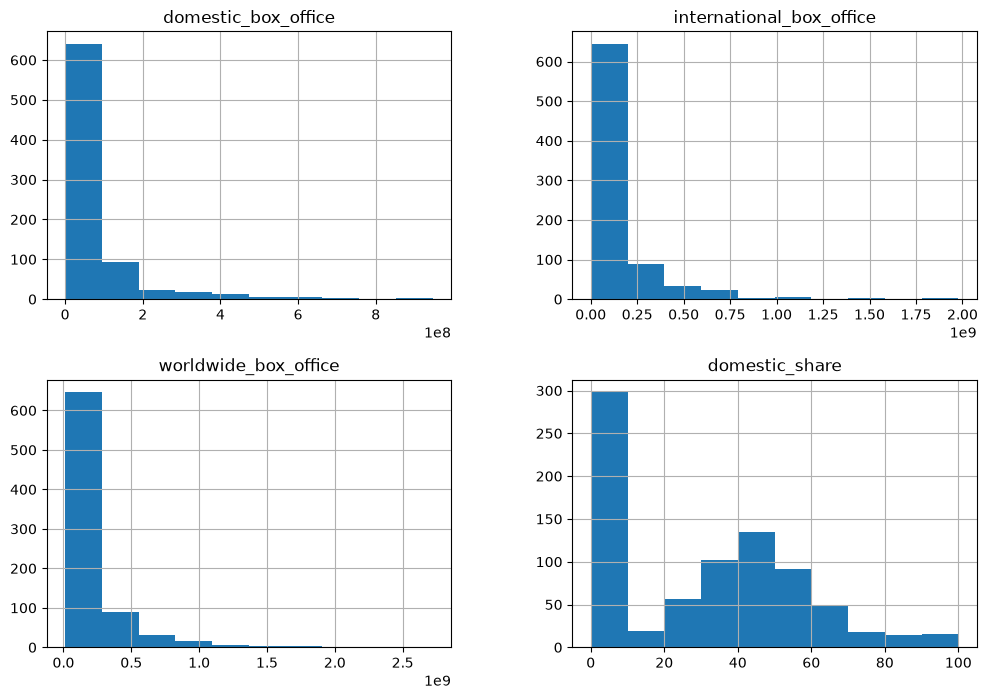

In [15]:
numbers_df[box_office_cols].hist(figsize=(12,8))

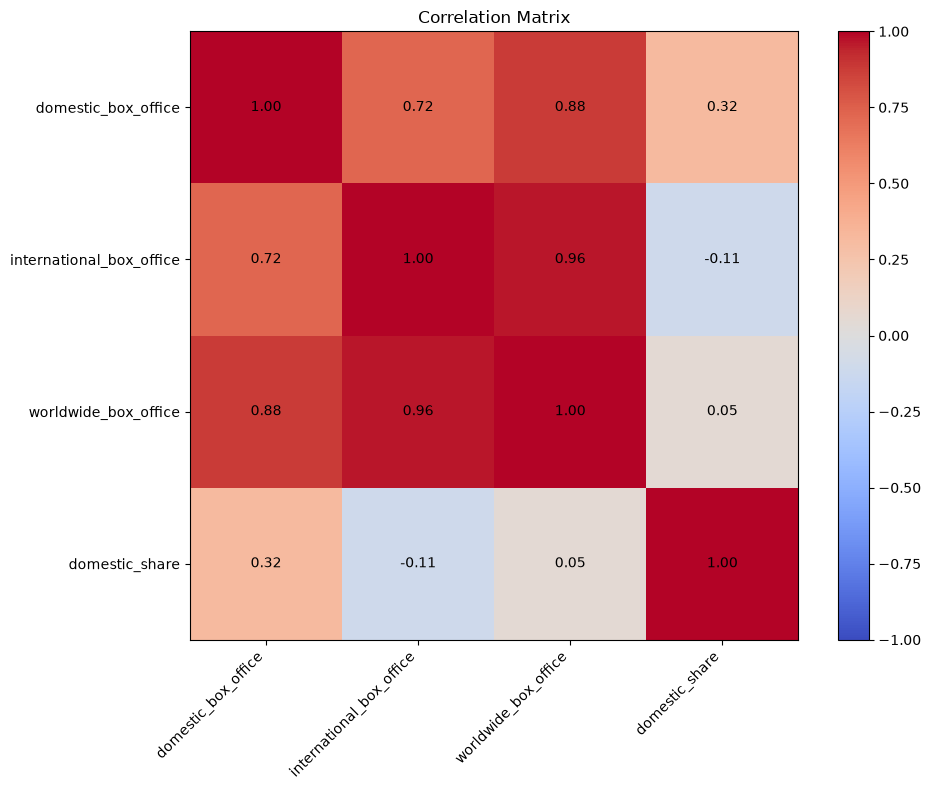

In [16]:
import matplotlib.pyplot as plt
corr = numbers_df[box_office_cols].corr()

plt.figure(figsize=(10, 8))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=45, ha="right")
plt.yticks(range(len(corr.columns)), corr.columns)

for i in range(len(corr)):
    for j in range(len(corr)):
        plt.text(j, i, f"{corr.iloc[i,j]:.2f}",
                 ha="center", va="center")

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

| Variables                                           | Pearson correlation | Interpretation                    |
| --------------------------------------------------- | ------------------: | --------------------------------- |
| `international_box_office` ↔ `worldwide_box_office` |           **0.966** | Very strong positive relationship |
| `domestic_box_office` ↔ `worldwide_box_office`      |           **0.886** | Very strong positive relationship |
| `domestic_box_office` ↔ `international_box_office`  |           **0.735** | Strong positive relationship      |


Les variables liées au box-office présentent de fortes corrélations positives. Le box-office mondial est notamment très fortement corrélé au box-office international (r = 0,966) et au box-office domestique (r = 0,886). Cette relation est cohérente avec la construction du box-office mondial à partir des recettes nationales et internationales

Text(0, 0.5, 'Box Office (in millions)')

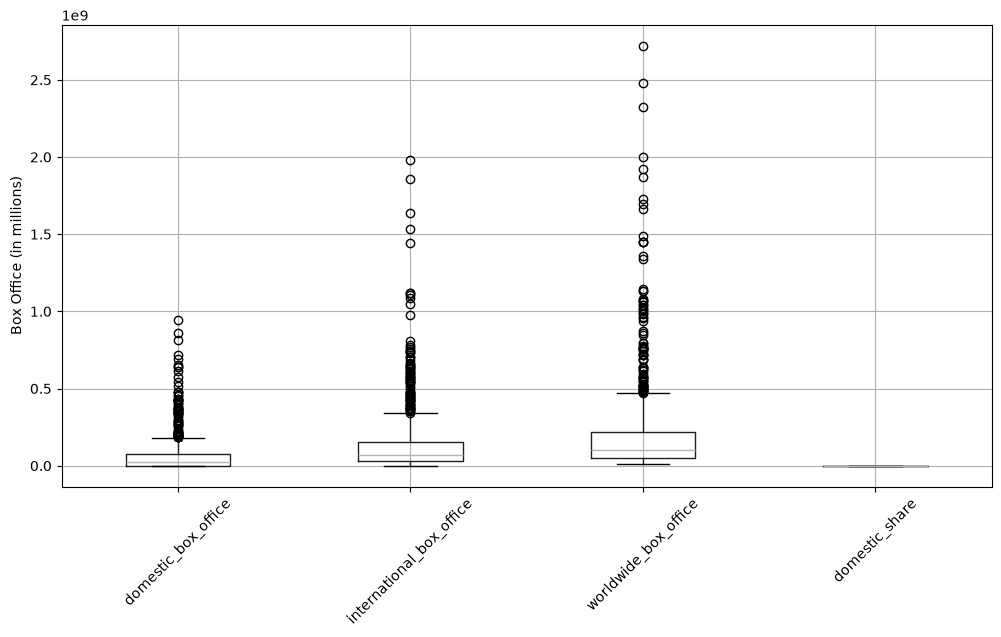

In [17]:
# box plots for box office columns
plt.figure(figsize=(12, 6))
numbers_df[box_office_cols].boxplot()
plt.xticks(rotation=45)
plt.ylabel("Box Office (in millions)")

the outliers probably represent blockbusters

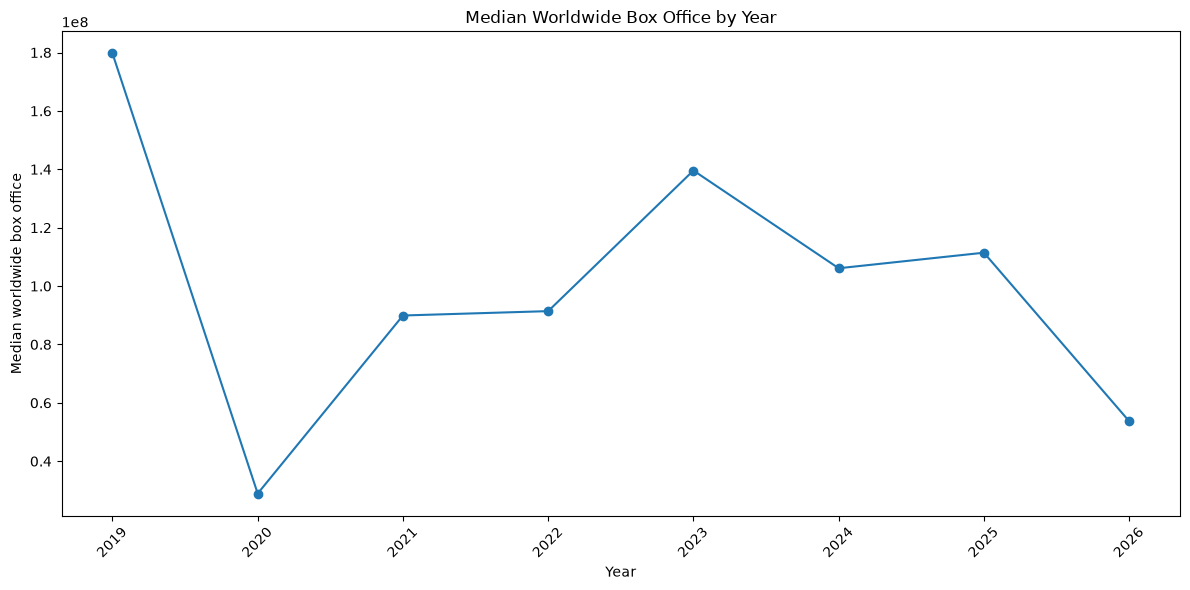

In [22]:
plt.figure(figsize=(12, 6))

plt.plot(
    year_analysis.index,
    year_analysis["median_worldwide"],
    marker="o"
)

plt.xlabel("Year")
plt.ylabel("Median worldwide box office")
plt.title("Median Worldwide Box Office by Year")
plt.xticks(year_analysis.index, rotation=45)
plt.tight_layout()
plt.show()

less movies before and during the covid period  --> financial crisis
then after the covid it sprung up

In [24]:
import numpy as np
import pandas as pd

bins = [0, 10, 25, 50, 75, 100]

labels = [
    "1-10",
    "11-25",
    "26-50",
    "51-75",
    "76-100"
]

numbers_df["rank_group"] = pd.cut(
    numbers_df["rank"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

numbers_df[["rank", "rank_group"]].sort_values("rank").head(30)

,rank,rank_group
600,1,1-10
500,1,1-10
0,1,1-10
300,1,1-10
100,1,1-10
400,1,1-10
700,1,1-10
200,1,1-10
701,2,1-10
201,2,1-10


In [26]:
rank_analysis = (
    numbers_df.groupby("rank_group", observed=True)
      .agg(
          n_movies=("worldwide_box_office", "count"),
          median_worldwide=("worldwide_box_office", "median"),
          mean_worldwide=("worldwide_box_office", "mean"),
          median_domestic=("domestic_box_office", "median"),
          median_international=("international_box_office", "median")
      )
      .reset_index()
)

rank_analysis

,rank_group,n_movies,median_worldwide,mean_worldwide,median_domestic,median_international
0,1-10,80,759928926.0,9.065267e+08,323455070.5,540372098.5
1,11-25,120,333949527.0,3.301734e+08,103342750.0,211896836.0
2,26-50,200,147177165.0,1.499477e+08,46860654.0,92388565.5
3,51-75,200,72328136.5,7.513150e+07,15410214.5,45752160.5
4,76-100,200,40408245.5,4.358546e+07,9753448.5,25528166.5


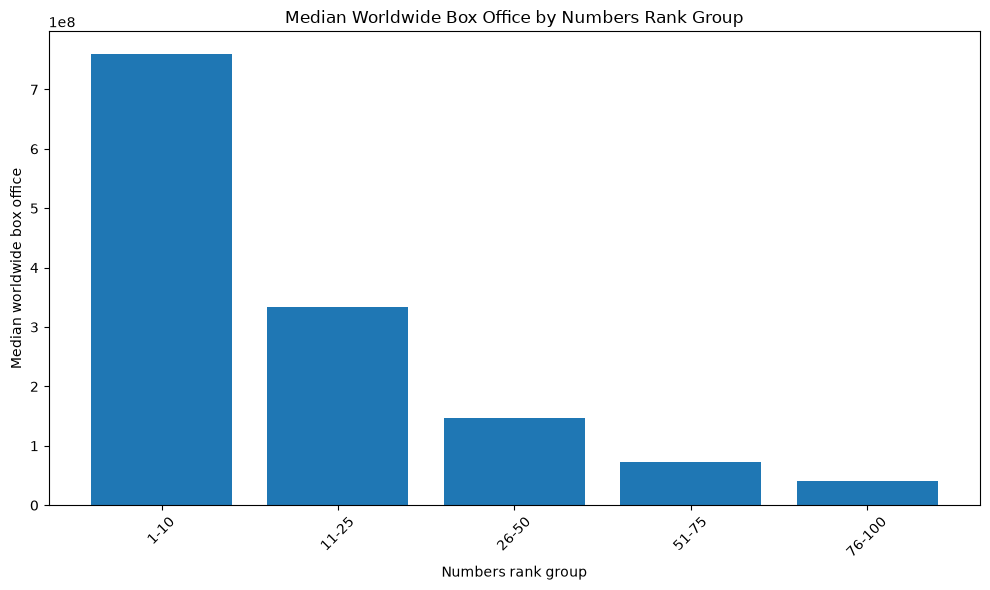

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(
    rank_analysis["rank_group"].astype(str),
    rank_analysis["median_worldwide"]
)

plt.xlabel("Numbers rank group")
plt.ylabel("Median worldwide box office")
plt.title("Median Worldwide Box Office by Numbers Rank Group")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

shows that rank is extracted from world wide box office

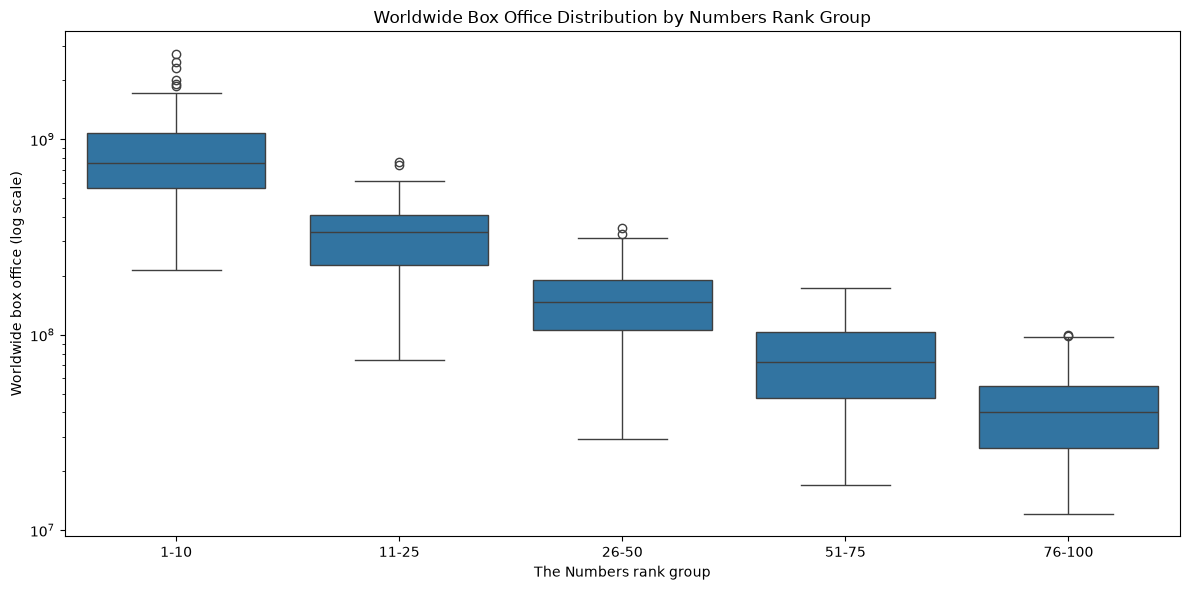

In [31]:
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=numbers_df,
    x="rank_group",
    y="worldwide_box_office"
)

plt.yscale("log")
plt.xlabel("The Numbers rank group")
plt.ylabel("Worldwide box office (log scale)")
plt.title("Worldwide Box Office Distribution by Numbers Rank Group")

plt.tight_layout()
plt.show()

shows how many blockbusters(outliers) in each ranked_group --> best of each rank_group

those outliers whithin each rank_group have the highest ranks because rank is positivly correlated with worlwide box office